---
# AutoML
Nessa atividade vamos novamente treinar/praticar com o dataset Íris novos comandos/conhecimentos de Machine Learning.

## Quais as instruções do professor?


*   Ambiente: O código deve ser executado em ambiente Python (Google Colab).

*   Bibliotecas necessárias: flaml, auto-sklearn, scikit-learn.

*   Etapas obrigatórias:

        * Carregar o dataset Iris e realizar a divisão entre treino e teste (ex: 80/20, com estratificação e random_state fixo).

        * Configurar e treinar um modelo utilizando o FLAML definindo um orçamento de tempo (time_budget).

        * Configurar e treinar um modelo utilizando o Auto-Sklearn com limites de tempo equivalentes.

        * Avaliar ambos os modelos utilizando métricas como acurácia e relatório de classificação (classification_report).

## O que será respondido ao final do notebook?

Um Pequeno relátório com estes tópicos!

* Desempenho: Qual dos frameworks obteve a melhor acurácia no conjunto de teste? Houve empate?

* Custo Computacional: Compare o tempo real de execução e o consumo de recursos relatados por cada ferramenta.

* Interpretabilidade / Pipelines: Qual ferramenta facilitou a inspeção do modelo escolhido ou do ensemble gerado?

---
# **Código**

In [1]:
!pip install flaml[automl] #instalando o flaml (Fast and Lightweight AutoM)
#que é uma biblioteca de automação usada na machine learning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 36.4 MB/s  0:00:06
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.5/336.5 MB 23.4 MB/s  0:00:12
  Attempting uninstall: xgboost
    Found existing installation: xgboost 3.4.1
    Uninstalling xgboost-3.4.1:
      Successfully uninstalled xgboost-3.4.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [xgboost]


In [2]:
!pip install auto-sklearn2 # aqui instalamos a biblioteca autosklean2 como uma
#alternativa por não conseguir fazer rodar as outras versão de python onde o
#autoskean consegue operar

In [3]:
# aqui importamos nossas bibliotecas como sempre
import pandas as pd
from sklearn.datasets import load_iris
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

from auto_sklearn2 import AutoSklearnClassifier

from flaml import AutoML
automl = AutoML()

np.random.seed(42)

In [4]:
iris = load_iris() #baixamos o dataser

In [5]:
df = pd.DataFrame(data=iris.data, columns=iris.feature_names) #organizamos o dataframe
# com os dados e rótulos

In [6]:
df['target'] = iris.target
df['species'] = df['target'].map(lambda x: iris.target_names[x])

In [7]:
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [8]:
df.isnull().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target,0
species,0


In [9]:
df.isna().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target,0
species,0


In [10]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [11]:
features = df.drop(['target', 'species'], axis=1)
target = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, random_state=42, stratify=target
) #configuramos nossos treinos e teste

In [12]:
settings = {
    "time_budget": 60,
    "metric": 'accuracy',
    "task": 'classification',
    "seed": 42,
} #aqui são as configurações solicitadas na atividade

In [13]:
automl.fit(X_train=X_train, y_train=y_train, **settings)

[flaml.automl.logger: 11-12 14:21:04] {2484} INFO - task = classification
[flaml.automl.logger: 11-12 14:21:04] {2495} INFO - Evaluation method: cv
[flaml.automl.logger: 11-12 14:21:04] {2604} INFO - Minimizing error metric: 1-accuracy
[flaml.automl.logger: 11-12 14:21:04] {2721} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd', 'lrl1']
[flaml.automl.logger: 11-12 14:21:04] {3026} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 11-12 14:21:04] {3161} INFO - Estimated sufficient time budget=1226s. Estimated necessary time budget=28s.
[flaml.automl.logger: 11-12 14:21:04] {3212} INFO -  at 0.2s,	estimator lgbm's best error=5.8333e-02,	best estimator lgbm's best error=5.8333e-02
[flaml.automl.logger: 11-12 14:21:04] {3026} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 11-12 14:21:04] {3212} INFO -  at 0.3s,	estimator lgbm's best error=5.8333e-02,	best estimator lgbm's best error=5.8333e-02
[flaml.auto

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 11-12 14:21:04] {3212} INFO -  at 0.5s,	estimator sgd's best error=5.5833e-01,	best estimator lgbm's best error=5.8333e-02
[flaml.automl.logger: 11-12 14:21:04] {3026} INFO - iteration 4, current learner lgbm
[flaml.automl.logger: 11-12 14:21:04] {3212} INFO -  at 0.6s,	estimator lgbm's best error=5.8333e-02,	best estimator lgbm's best error=5.8333e-02
[flaml.automl.logger: 11-12 14:21:04] {3026} INFO - iteration 5, current learner xgboost
[flaml.automl.logger: 11-12 14:21:04] {3212} INFO -  at 0.7s,	estimator xgboost's best error=5.0000e-02,	best estimator xgboost's best error=5.0000e-02
[flaml.automl.logger: 11-12 14:21:04] {3026} INFO - iteration 6, current learner xgboost
[flaml.automl.logger: 11-12 14:21:05] {3212} INFO -  at 0.8s,	estimator xgboost's best error=4.1667e-02,	best estimator xgboost's best error=4.1667e-02
[flaml.automl.logger: 11-12 14:21:05] {3026} INFO - iteration 7, current learner lgbm
[flaml.automl.logger: 11-12 14:21:05] {3212} INFO -  at

In [14]:
accuracy_flaml = automl.score(X_train, y_train)
print('Melhor modelo de ML:', automl.best_estimator)
print('Melhor configuração de hiperparâmetros:', automl.best_config)
print('Melhor acurácia nos dados de validação: {0:.4g}'.format(1-automl.best_loss))
print('Duração do treinamento da melhor execução: {0:.4g} s'.format(automl.best_config_train_time))

#aqui o flaml já fez todo o trabalho que anteriormente era manual das analises e
#nos retornou só com os melhores dados desses treinos

Melhor modelo de ML: lgbm
Melhor configuração de hiperparâmetros: {'n_estimators': 17, 'num_leaves': 5, 'min_child_samples': 26, 'learning_rate': np.float64(0.7088624964104729), 'log_max_bin': 8, 'colsample_bytree': 1.0, 'reg_alpha': np.float64(0.031053314852989265), 'reg_lambda': np.float64(0.28811162808869856)}
Melhor acurácia nos dados de validação: 0.9667
Duração do treinamento da melhor execução: 0.0155 s


In [15]:
best_model = automl.model.estimator
y_pred = best_model.predict(X_test)
#partimos então para os teste do flaml

In [16]:
report = classification_report(y_test, y_pred, target_names=iris.target_names)
print("Relatório de Classificação:")
print(report)

Relatório de Classificação:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



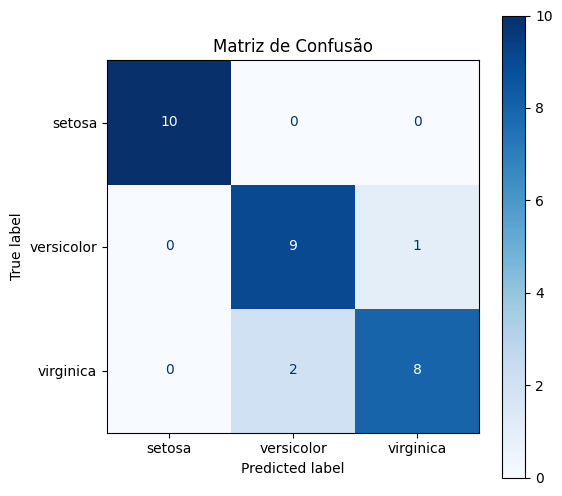

In [17]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Matriz de Confusão")
plt.show()

In [18]:
autosklearn = AutoSklearnClassifier(
    time_limit=60,
    random_state=42
)
#aqui começamos o mesmo processo, mas com o autosklearn

In [19]:
autosklearn.fit(X_train, y_train)

ERROR:auto_sklearn2:Error evaluating standard_scaler + multinomial_nb: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/pipeline.py", line 662, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/l

AutoSklearnClassifier(random_state=42, time_limit=60)

In [20]:
accuracy_autosklearn = autosklearn.score(X_train, y_train)
print('Melhor modelo de ML:', autosklearn.best_params)
print('Melhor acurácia nos dados de validação: {0:.4g}'.format(autosklearn.score(X_train, y_train)))

Melhor modelo de ML: {'preprocessor': 'standard_scaler', 'classifier': 'lda'}
Melhor acurácia nos dados de validação: 0.975


In [21]:
y_pred = autosklearn.predict(X_test)
report = classification_report(y_test, y_pred, target_names=iris.target_names)
print("Relatório de Classificação:")
print(report)

Relatório de Classificação:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



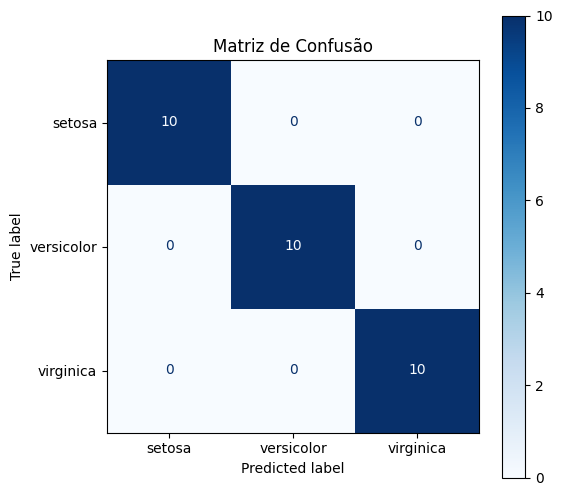

In [22]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Matriz de Confusão")
plt.show()

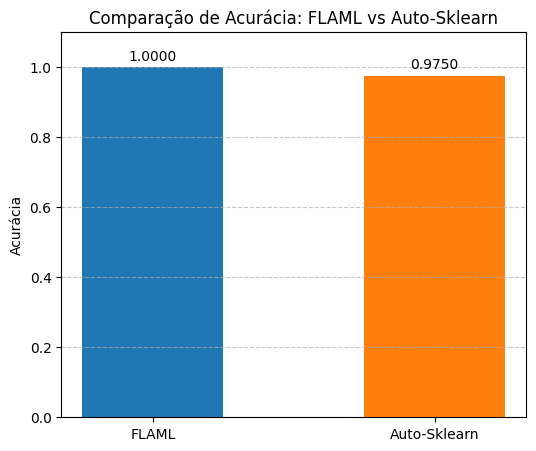

In [23]:
frameworks = ['FLAML', 'Auto-Sklearn']
acuracias = [accuracy_flaml, accuracy_autosklearn]

plt.figure(figsize=(6, 5))
bars = plt.bar(frameworks, acuracias, color=['#1f77b4', '#ff7f0e'], width=0.5)

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.4f}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3),  # 3 pontos de deslocamento vertical
                 textcoords="offset points",
                 ha='center', va='bottom')

plt.ylim(0, 1.1)
plt.ylabel('Acurácia')
plt.title('Comparação de Acurácia: FLAML vs Auto-Sklearn')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

---
# **Respostas**

**Desempenho:** O auto-sklearn2 obteve o melhor resultado no conjunto de teste: acurácia de **1,00** (30/30 acertos), contra **0,93** do FLAML. Não houve empate. No FLAML, o melhor modelo foi um `ExtraTreesClassifier` com acurácia de validação de **0,9667**, mas ele errou 2 exemplos no teste (matriz de confusão com confusões entre versicolor e virginica). Vale notar que o valor **0,975** exibido para o auto-sklearn foi calculado com `score(X_train, y_train)`, ou seja, é acurácia de treino, não de validação; o desempenho relevante no teste foi 1,00. Como o teste tem apenas 30 amostras, cada erro vale 3,3 pontos percentuais, então a diferença deve ser interpretada com cautela.

**Custo computacional:** Ambos foram configurados com limite de 60 segundos, mas o FLAML forneceu logs bem mais detalhados: executou 226 iterações, testou vários learners, encontrou o melhor modelo em cerca de **35,8 s** e reportou treinamento da melhor configuração em **0,0189 s**; o modelo final usou `n_jobs=-1`, indicando uso de todos os núcleos disponíveis. O auto-sklearn2 não relatou no notebook o tempo real decorrido nem consumo de CPU/memória; sabendo apenas que o `time_limit` era 60 s. Ele também registrou erros em pipelines com `MultinomialNB` por valores negativos na entrada, mas isso não impediu a seleção final do pipeline `standard_scaler + lda`. Assim, com os dados disponíveis, o custo do FLAML é mensurável e transparente; o do auto-sklearn é menos auditável.

**Interpretabilidade/pipelines:** O auto-sklearn2 facilitou um pouco mais a inspeção do pipeline final, porquê expôs diretamente `{'preprocessor': 'standard_scaler', 'classifier': 'lda'}`, uma combinação simples e interpretável. O FLAML também permite inspecionar o modelo final (`automl.model.estimator`) e a configuração escolhida (`n_estimators=4`, `max_leaves=6`, `max_features≈0,551`, `criterion='entropy'`), que é um modelo relativamente simples, mas seus logs são mais extensos e voltados ao processo de busca. Concluimos que o auto-sklearn2 teve melhor acurácia no *teste* e pipeline final mais direto de inspecionar, já o FLAML, teve custo computacional melhor documentado.